In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# Loading the cleaned datasets from Notebook 01
project_path = os.path.dirname(os.getcwd())
data_path = os.path.join(project_path, "data")

df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))
matches_df = pd.read_csv(os.path.join(data_path, "matches.csv"))

matches_df["date"] = pd.to_datetime(matches_df["date"])

print("Deliveries:", df.shape)
print("Matches:", matches_df.shape)

Deliveries: (295732, 23)
Matches: (1243, 10)


C:\Users\sw\AppData\Local\Temp\ipykernel_19356\3017665985.py:10: DtypeWarning: Columns (0: season) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(os.path.join(data_path, "deliveries_clean.csv"))


In [2]:
# Summarizing each innings
innings_stats = df.groupby(
    ["match_id", "innings", "batting_team"]
).agg(
    total_runs=("runs_total", "sum"),
    total_wickets=("total_wickets", "sum"),
    legal_balls=("is_legal_delivery", "sum")
).reset_index()

innings_stats["run_rate"] = (
    innings_stats["total_runs"] /
    (innings_stats["legal_balls"] / 6)
).round(2)

innings_stats.head()

,match_id,innings,batting_team,total_runs,total_wickets,legal_balls,run_rate
0,335982,1,Kolkata Knight Riders,222,3,120,11.10
1,335982,2,Royal Challengers Bangalore,82,10,91,5.41
2,335983,1,Chennai Super Kings,240,5,120,12.00
3,335983,2,Kings XI Punjab,207,4,120,10.35
4,335984,1,Rajasthan Royals,129,8,120,6.45


In [3]:
# Calculating total runs scored by each team
team_stats = df.groupby("batting_team").agg(
    total_runs=("runs_total", "sum"),
    total_fours=("runs_batter", lambda x: (x == 4).sum()),
    total_sixes=("runs_batter", lambda x: (x == 6).sum()),
    matches_played=("match_id", "nunique")
).reset_index()

team_stats = team_stats.sort_values(
    "total_runs", ascending=False
)

team_stats

,batting_team,total_runs,total_fours,total_sixes,matches_played
10,Mumbai Indians,47641,4101,1968,291
8,Kolkata Knight Riders,43646,3826,1711,278
0,Chennai Super Kings,43600,3615,1735,265
13,Rajasthan Royals,40437,3559,1564,250
16,Royal Challengers Bangalore,37692,3149,1488,240
18,Sunrisers Hyderabad,34640,2879,1333,210
6,Kings XI Punjab,30064,2631,1075,190
3,Delhi Daredevils,24296,2156,801,161
2,Delhi Capitals,19959,1798,777,119
12,Punjab Kings,15509,1281,782,87


In [4]:
# Counting match wins for each team
team_wins = (
    matches_df["winner"]
    .dropna()
    .value_counts()
    .reset_index()
)

team_wins.columns = ["team", "wins"]

team_wins

,team,wins
0,Mumbai Indians,155
1,Chennai Super Kings,148
2,Kolkata Knight Riders,140
3,Rajasthan Royals,123
4,Royal Challengers Bangalore,114
5,Sunrisers Hyderabad,102
6,Kings XI Punjab,85
7,Delhi Daredevils,67
8,Delhi Capitals,58
9,Gujarat Titans,47


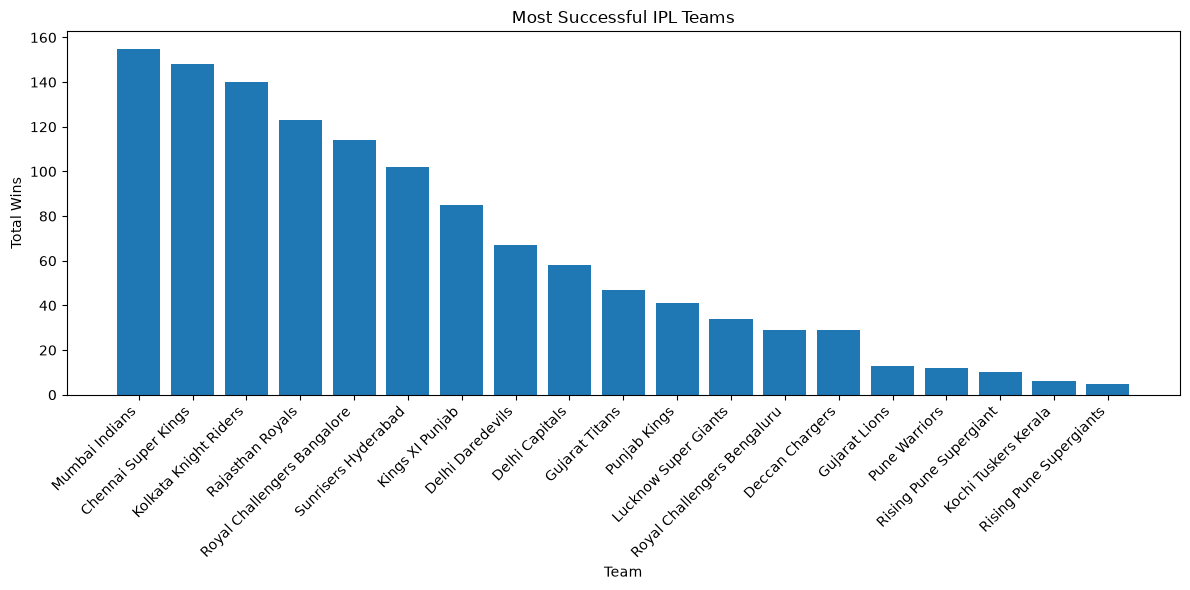

In [5]:
plt.figure(figsize=(12, 6))

plt.bar(team_wins["team"], team_wins["wins"])

plt.title("Most Successful IPL Teams")
plt.xlabel("Team")
plt.ylabel("Total Wins")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [6]:
# Counting the decisions made after winning the toss
toss_decisions = (
    matches_df["toss_decision"]
    .value_counts()
    .reset_index()
)

toss_decisions.columns = ["decision", "count"]

print(toss_decisions)

  decision  count
0    field    825
1      bat    418


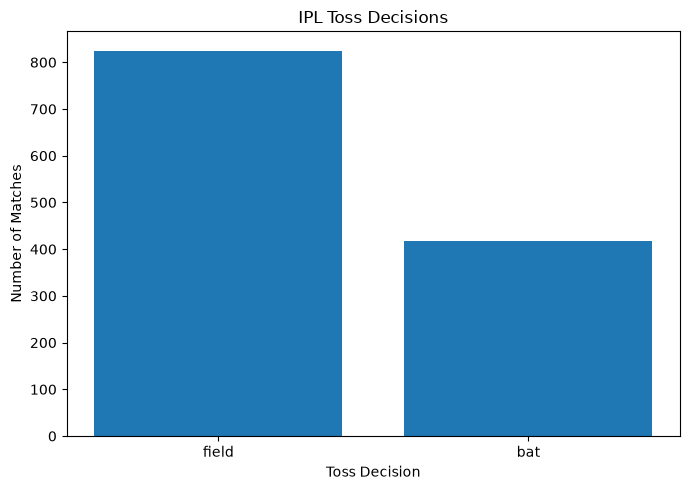

In [7]:
plt.figure(figsize=(7, 5))

plt.bar(toss_decisions["decision"], toss_decisions["count"])

plt.title("IPL Toss Decisions")
plt.xlabel("Toss Decision")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.show()

In [8]:
# Comparing toss winners with match winners
matches_with_winner = matches_df.dropna(subset=["winner"]).copy()

matches_with_winner["toss_match_result"] = (
    matches_with_winner["toss_winner"] ==
    matches_with_winner["winner"]
)

toss_result = (
    matches_with_winner["toss_match_result"]
    .value_counts()
    .rename(index={True: "Won Match", False: "Lost Match"})
    .reset_index()
)

toss_result.columns = ["result", "count"]

toss_result

,result,count
0,Won Match,628
1,Lost Match,590


In [9]:
# Identifying whether the match winner batted first or chased
first_innings = innings_stats[
    innings_stats["innings"] == 1
][["match_id", "batting_team"]].rename(
    columns={"batting_team": "batting_first"}
)

second_innings = innings_stats[
    innings_stats["innings"] == 2
][["match_id", "batting_team"]].rename(
    columns={"batting_team": "chasing_team"}
)

match_comparison = matches_with_winner[
    ["match_id", "winner"]
].merge(first_innings, on="match_id", how="left").merge(
    second_innings, on="match_id", how="left"
)

match_comparison["winning_type"] = np.where(
    match_comparison["winner"] == match_comparison["batting_first"],
    "Batting First",
    np.where(
        match_comparison["winner"] == match_comparison["chasing_team"],
        "Chasing",
        "Other"
    )
)

match_comparison["winning_type"].value_counts()

winning_type
Chasing          666
Batting First    552
Name: count, dtype: int64

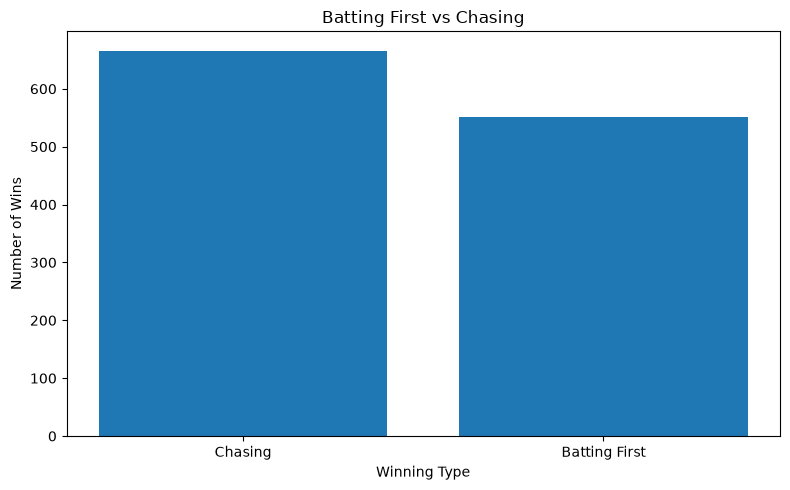

In [10]:
winning_stats = (
    match_comparison["winning_type"]
    .value_counts()
    .reset_index()
)

winning_stats.columns = ["winning_type", "wins"]

plt.figure(figsize=(8, 5))

plt.bar(winning_stats["winning_type"], winning_stats["wins"])

plt.title("Batting First vs Chasing")
plt.xlabel("Winning Type")
plt.ylabel("Number of Wins")

plt.tight_layout()
plt.show()

In [11]:
# Counting matches played at each venue
venue_stats = (
    matches_df["venue"]
    .value_counts()
    .reset_index()
)

venue_stats.columns = ["venue", "matches"]

venue_stats.head(15)

,venue,matches
0,"Wankhede Stadium, Mumbai",132
1,"Eden Gardens, Kolkata",107
2,MA Chidambaram Stadium,98
3,"Rajiv Gandhi International Stadium, Uppal",90
4,"Feroz Shah Kotla, Delhi",74
5,"Sawai Mansingh Stadium, Jaipur",68
6,"M Chinnaswamy Stadium, Bengaluru",62
7,Dubai International Cricket Stadium,46
8,"Narendra Modi Stadium, Ahmedabad",45
9,"Maharashtra Cricket Association Stadium, Pune",42


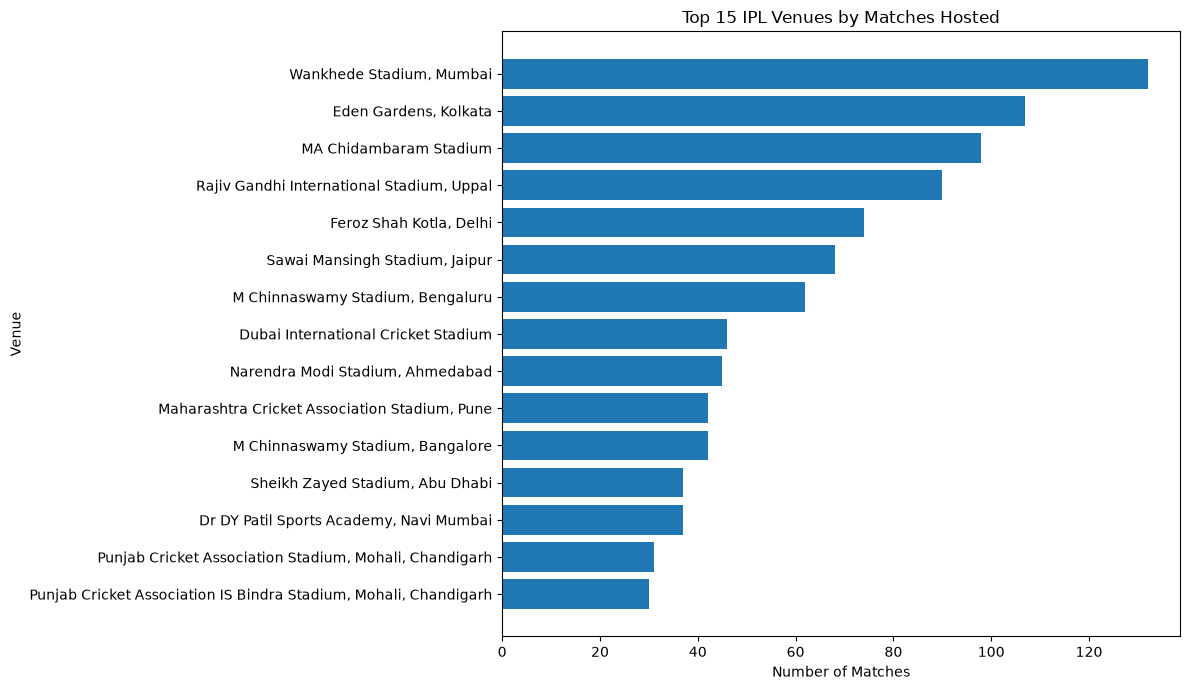

In [12]:
# Showing the 15 most frequently used venues
top_venues = venue_stats.head(15)

plt.figure(figsize=(12, 7))

plt.barh(top_venues["venue"], top_venues["matches"])

plt.title("Top 15 IPL Venues by Matches Hosted")
plt.xlabel("Number of Matches")
plt.ylabel("Venue")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()


In [13]:
# Connecting match winners with their venues
team_venue_stats = matches_df.dropna(
    subset=["winner", "venue"]
).groupby(
    ["venue", "winner"]
).size().reset_index(name="wins")

team_venue_stats = team_venue_stats.sort_values(
    "wins", ascending=False
)

team_venue_stats.head(20)

,venue,winner,wins
326,"Wankhede Stadium, Mumbai",Mumbai Indians,58
79,"Eden Gardens, Kolkata",Kolkata Knight Riders,57
154,MA Chidambaram Stadium,Chennai Super Kings,55
244,"Rajiv Gandhi International Stadium, Uppal",Sunrisers Hyderabad,42
264,"Sawai Mansingh Stadium, Jaipur",Rajasthan Royals,39
91,"Feroz Shah Kotla, Delhi",Delhi Daredevils,27
138,"M Chinnaswamy Stadium, Bangalore",Royal Challengers Bangalore,21
193,"Narendra Modi Stadium, Ahmedabad",Gujarat Titans,18
151,"M Chinnaswamy Stadium, Bengaluru",Royal Challengers Bangalore,18
222,"Punjab Cricket Association Stadium, Mohali, Ch...",Kings XI Punjab,17


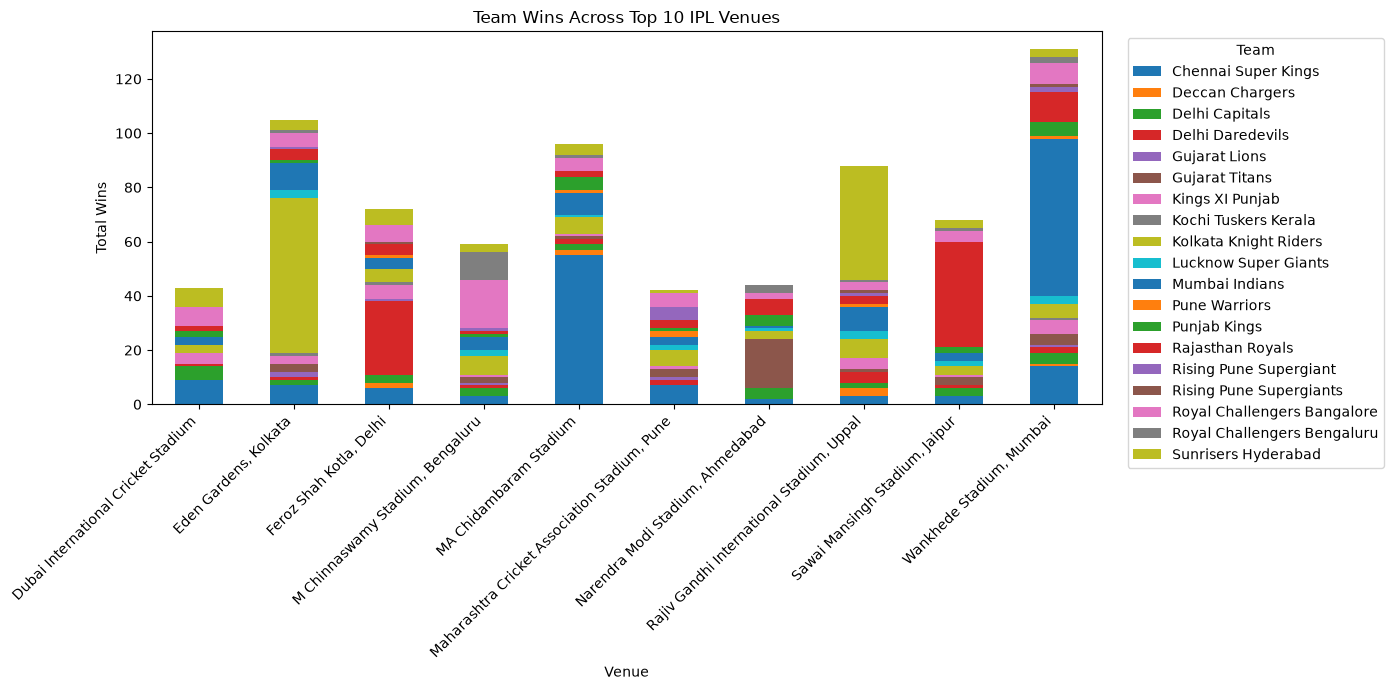

In [14]:
# Comparing team wins across the most active venues
top_venue_names = venue_stats.head(10)["venue"]

venue_chart_data = team_venue_stats[
    team_venue_stats["venue"].isin(top_venue_names)
]

venue_pivot = venue_chart_data.pivot(
    index="venue",
    columns="winner",
    values="wins"
).fillna(0)

venue_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Team Wins Across Top 10 IPL Venues")
plt.xlabel("Venue")
plt.ylabel("Total Wins")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Team", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()